In [25]:
!pip install openpyxl matplotlib

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [3]:
np.random.seed(4)
n = 100
dates = pd.date_range(start='2050-01-01', periods=n, freq='D') # periods means n days
products = np.random.choice(['Tablet', 'Camera', 'Phone', 'Laptop', 'TV', 'PC', 'Speakers', 'Microphone', 'Earphones', 'Headphones', 'Screen', 'Gamepad'], n) 
prices = np.round(np.random.uniform(50.0, 200.0, n), 2)
quantities = np.random.randint(1, 15, size=n)

data = {
    'Date': dates,
    'Product': products,
    'Price': prices,
    'Quantitiy': quantities
}

df = pd.DataFrame(data)
df.head()

,Date,Product,Price,Quantitiy
0,2050-01-01,Screen,160.02,2
1,2050-01-02,Microphone,154.85,12
2,2050-01-03,PC,150.43,14
3,2050-01-04,Camera,62.00,1
4,2050-01-05,Earphones,56.70,6


In [15]:
df.dtypes

Date         datetime64[us]
Product                 str
Price               float64
Quantitiy             int32
dtype: object

In [17]:
df.to_csv('random_sales.csv', index=False) # index=False means that column index won't be created

In [44]:
df = pd.read_csv('random_sales.csv', parse_dates=['Date'], date_format='%Y-%m-%d') # read_csv create a DataFrame. Returns DataFrame. 
# parse_dates=['Date'] means convert them to datetime type (opt)
# date_format='%Y-%m-%d' change date format (opt)
df.head()

,Date,Product,Price,Quantitiy
0,2050-01-01,Screen,160.02,2
1,2050-01-02,Microphone,154.85,12
2,2050-01-03,PC,150.43,14
3,2050-01-04,Camera,62.00,1
4,2050-01-05,Earphones,56.70,6


In [45]:
df.dtypes

Date         datetime64[us]
Product                 str
Price               float64
Quantitiy             int64
dtype: object

In [27]:
df.to_excel('sales_data.xlsx')

In [47]:
df.to_json('sales_data.json', date_format='iso') # JSON - java script object notation

In [48]:
df = pd.read_excel('sales_data.xlsx')
df.head()

,Unnamed: 0,Date,Product,Price,Quantitiy
0,0,2050-01-01,Screen,160.02,2
1,1,2050-01-02,Microphone,154.85,12
2,2,2050-01-03,PC,150.43,14
3,3,2050-01-04,Camera,62.00,1
4,4,2050-01-05,Earphones,56.70,6


In [50]:
df = pd.read_json('sales_data.json')
df.head()

,Date,Product,Price,Quantitiy
0,2050-01-01,Screen,160.02,2
1,2050-01-02,Microphone,154.85,12
2,2050-01-03,PC,150.43,14
3,2050-01-04,Camera,62.00,1
4,2050-01-05,Earphones,56.70,6


In [51]:
df.shape

(100, 4)

In [53]:
df.describe().round(2)

,Date,Price,Quantitiy
count,100,100.00,100.00
mean,2050-02-19 12:00:00,124.97,7.47
min,2050-01-01 00:00:00,50.44,1.00
25%,2050-01-25 18:00:00,79.22,4.00
50%,2050-02-19 12:00:00,125.50,8.00
75%,2050-03-16 06:00:00,166.58,11.00
max,2050-04-10 00:00:00,199.61,14.00
std,NaN,47.00,3.98


In [57]:
df.values[0:5]

array([[Timestamp('2050-01-01 00:00:00'), 'Screen', 160.02, 2],
       [Timestamp('2050-01-02 00:00:00'), 'Microphone', 154.85, 12],
       [Timestamp('2050-01-03 00:00:00'), 'PC', 150.43, 14],
       [Timestamp('2050-01-04 00:00:00'), 'Camera', 62.0, 1],
       [Timestamp('2050-01-05 00:00:00'), 'Earphones', 56.7, 6]],
      dtype=object)

In [4]:
product_sales = df.groupby('Product')['Quantitiy'].sum() # Calculate all products' quantities
product_sales

Product
Camera         54
Earphones      85
Gamepad        52
Headphones     51
Laptop         60
Microphone    117
PC             91
Phone          75
Screen         37
Speakers       32
TV             51
Tablet         42
Name: Quantitiy, dtype: int32

In [10]:
avg_prices = df.groupby('Product')['Price'].mean().round(2) # Calculate average price per every product
avg_prices

Product
Camera         90.24
Earphones     122.99
Gamepad       126.27
Headphones    150.61
Laptop        119.99
Microphone    121.34
PC            139.23
Phone         130.02
Screen        113.25
Speakers      109.41
TV            140.55
Tablet        124.77
Name: Price, dtype: float64

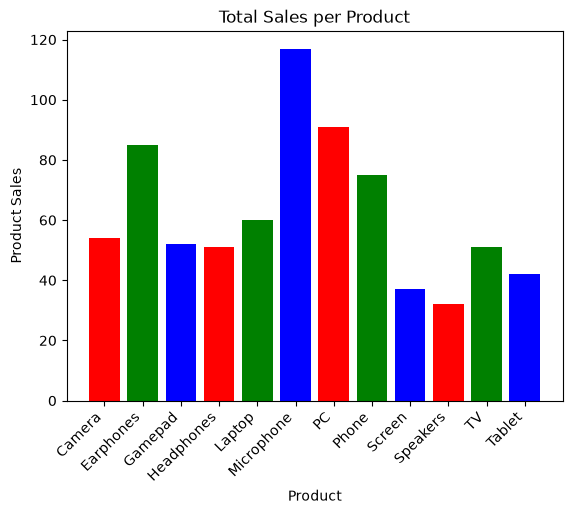

In [8]:
plt.bar(product_sales.index, product_sales.values, color=['red', 'green', 'blue'])
plt.title('Total Sales per Product')
plt.xlabel('Product')
plt.ylabel('Product Sales')
plt.xticks(rotation=45, ha='right')
plt.show()

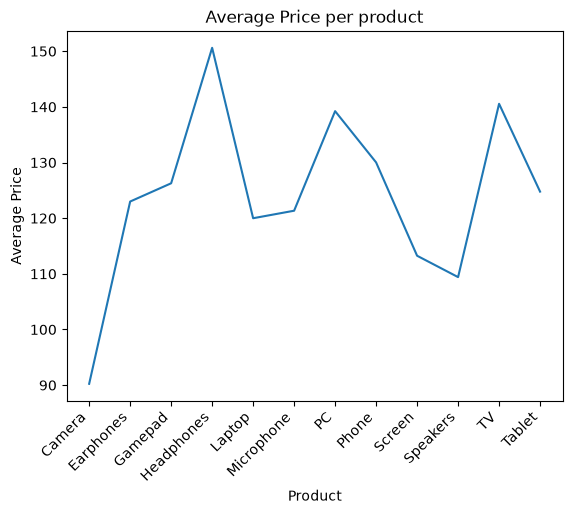

In [13]:
plt.plot(avg_prices.index, avg_prices.values)
plt.title('Average Price per product')
plt.xlabel('Product')
plt.ylabel('Average Price')
plt.xticks(rotation=45, ha='right')
plt.show()